# M4 · Orders Cleaning (pandas + NumPy)

**Goal:** clean all 300,000 orders so amounts, dates, quantities, payment methods and statuses can be trusted for reporting.

NumPy is used for the numeric work: IQR outlier fences, placeholder detection from value frequencies, and vectorised rules with `np.select`.
Every step refers to an `issue_id` from the M1 issue log. Values that cannot be proven are set to null and **flagged**, never invented.

**Outputs**
| File | Folder | Content |
|---|---|---|
| `orders_clean.xlsx` | `clean_data/` | sheets `orders` (300,000 clean orders with outlier marker and review flags), `flagged` (one row per problem, with the raw value), `mappings` (every raw variant of payment method, status and quantity with its clean value) |
| `orders_clean.csv` | `clean_data/csv/` | the same clean orders as UTF-8 CSV |
| `m4_fix_log.xlsx`, `m4_amount_distribution.png` | `output/` (this folder) | fixes linked to M1 issues, validation, amount chart |

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW_DIR = Path("../../01_data_and_task/raw_data")
CLEAN_DIR = Path("../../03_clean_data_and_report/clean_data")
OUT_DIR = Path("output")  # detailed working outputs of this milestone (logs, charts)
OUT_DIR.mkdir(exist_ok=True)
ISSUE_LOG = Path("../01_profiling-pandas/output/issue_log.xlsx")

# The raw files were exported on 2025-12-02; an order after that day cannot be real.
AFTER_SNAPSHOT = pd.Timestamp("2025-12-03")

raw = pd.read_csv(RAW_DIR / "orders_300k_dirty.csv", dtype=str, keep_default_na=False, encoding="utf-8")
customers = pd.read_excel(CLEAN_DIR / "customers_clean.xlsx", sheet_name="customers", usecols=["customer_id"])
products = pd.read_excel(CLEAN_DIR / "products_clean.xlsx", sheet_name="products_clean", usecols=["product_id", "price"])

issue_log = pd.read_excel(ISSUE_LOG, sheet_name="issue_log")
m4_issues = issue_log[issue_log["milestone"] == "M4"]
print(f"raw orders: {len(raw):,}")
m4_issues[["issue_id", "column", "issue", "rows_affected"]]

raw orders: 300,000


,issue_id,column,issue,rows_affected
34,ISS-035,status,"non-standard value (7 variants: case, typos, a...",90000
35,ISS-036,payment_method,"non-standard value (7 variants: case, typos, a...",75000
36,ISS-037,status,leading/trailing spaces,25658
37,ISS-038,order_amount,leading/trailing spaces,25592
38,ISS-039,payment_method,leading/trailing spaces,21553
39,ISS-040,order_date,impossible date '2024/31/01' (month 31),18110
40,ISS-041,order_date,date in DD-MM-YYYY format (all rows hold the s...,18050
41,ISS-042,order_date,full timestamp instead of a date (YYYY-MM-DDTH...,17974
42,ISS-043,order_date,order date after the data export date (future),17974
43,ISS-044,order_date,"date with time in YYYY/MM/DD HH:MM format, day...",17952


## 2. Helpers

In [2]:
fix_log = []
flags = []


def iid(column, issue_start):
    hit = m4_issues[(m4_issues["column"] == column) & m4_issues["issue"].str.startswith(issue_start)]
    assert len(hit) == 1, f"expected one issue for {column!r} / {issue_start!r}, found {len(hit)}"
    return hit["issue_id"].iloc[0]


def log_fix(issue_id, action, fixed=0, flagged=0):
    row = m4_issues.set_index("issue_id").loc[issue_id]
    fix_log.append({
        "issue_id": issue_id, "column": row["column"], "issue": row["issue"],
        "rows_in_m1": int(row["rows_affected"]), "rows_fixed": int(fixed), "rows_flagged": int(flagged),
        "action_taken": action,
    })


def flag(mask, column, reason):
    flags.append(pd.DataFrame({
        "order_id": raw.loc[mask, "order_id"], "column": column,
        "raw_value": raw.loc[mask, column], "reason": reason,
    }))
    return int(mask.sum())


orders = raw[["order_id", "customer_id", "product_id"]].copy()
stripped = raw.apply(lambda s: s.str.strip())

## 3. Trim spaces

Trimming alone fixes the space issues; the trimmed values are then cleaned column by column below.

In [3]:
for col in ["status", "order_amount", "payment_method"]:
    log_fix(iid(col, "leading/trailing spaces"), "Trimmed", fixed=raw[col].ne(stripped[col]).sum())

## 4. Payment method and status

Each raw value is reduced to a key (lower case, letters only) and mapped through an explicit table. The tables are saved in the `mappings` sheet of `orders_clean.xlsx` so the client can check every decision.

In [4]:
def letters_key(s):
    return s.str.lower().str.replace(r"[^a-z]", "", regex=True)


PAYMENT_MAP = {"card": "card", "crad": "card", "crd": "card", "cd": "card",
               "cash": "cash", "upi": "upi", "wallet": "wallet"}
STATUS_MAP = {"success": "success", "suc": "success",
              "failed": "failed", "fail": "failed",
              "refunded": "refunded", "ref": "refunded"}

mappings = {}
for col, mapping in [("payment_method", PAYMENT_MAP), ("status", STATUS_MAP)]:
    key = letters_key(stripped[col])
    unmapped = sorted(set(key) - set(mapping))
    assert not unmapped, f"{col}: unmapped keys {unmapped}"
    orders[col] = key.map(mapping)
    changed = raw[col].ne(orders[col])
    log_fix(iid(col, "non-standard value"), f"Mapped to {sorted(set(mapping.values()))} via mapping table",
            fixed=(stripped[col].ne(orders[col])).sum())
    mappings[col] = (
        pd.DataFrame({"raw_value": raw[col], "key": key, "clean_value": orders[col]})
        .value_counts().rename("rows").reset_index()
        .sort_values(["clean_value", "rows"], ascending=[True, False])
    )
    print(col, orders[col].value_counts().to_dict())

mappings["status"]

payment_method {'card': 88294, 'wallet': 77691, 'upi': 77569, 'cash': 56446}


status {'success': 221280, 'refunded': 42827, 'failed': 35893}


,raw_value,key,clean_value,rows
7,fail,fail,failed,12760
8,FAILED,failed,failed,12722
9,failed,failed,failed,10411
1,refunded,refunded,refunded,16990
3,refunded,refunded,refunded,12936
4,REF,ref,refunded,12901
0,success,success,success,182599
2,SUCCESS,success,success,12955
5,suc,suc,success,12874
6,Success,success,success,12852


## 5. Order amount

- `NaN` text, `0`, `-50` and `1,200` are not real amounts: M1 showed that each of these values sits on about 12,900 orders (all rows identical), so they are injected placeholders. They become null and are flagged.
- Note: `order_amount` is **not** derived from product price × quantity in this dataset (the median ratio is about 0.39 and it varies widely), so missing amounts cannot be rebuilt from the catalog.
- **Outliers:** the IQR rule is computed with NumPy on the valid amounts. Outliers are **kept** and marked with `is_amount_outlier`; they may be genuine bulk orders and only the client can decide.

In [5]:
amount_text = stripped["order_amount"]
amount = pd.to_numeric(amount_text, errors="coerce")  # '1,200' and 'NaN' text -> NaN here

rules = {
    "placeholder text 'NaN'": amount_text.str.lower().eq("nan"),
    "thousand-separator placeholder '1,200'": amount_text.str.contains(",", regex=False),
    "negative amount": amount < 0,
    "zero amount": amount == 0,
}
for reason, mask in rules.items():
    flag(mask, "order_amount", f"{reason}; set to null")
amount = amount.where(amount > 0)
orders["order_amount"] = amount.round(2)

log_fix(iid("order_amount", "placeholder text"), "Set to null and flagged", flagged=rules["placeholder text 'NaN'"].sum())
log_fix(iid("order_amount", "non-numeric amount"), "Repeated placeholder: set to null and flagged",
        flagged=rules["thousand-separator placeholder '1,200'"].sum())
log_fix(iid("order_amount", "negative amount"), "Set to null and flagged", flagged=rules["negative amount"].sum())
log_fix(iid("order_amount", "zero amount"), "Set to null and flagged", flagged=rules["zero amount"].sum())

# NumPy IQR fences on the valid amounts
valid = orders["order_amount"].dropna().to_numpy()
q1, q3 = np.percentile(valid, [25, 75])
iqr = q3 - q1
lower, upper = max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr
orders["is_amount_outlier"] = orders["order_amount"].gt(upper)
n_out = flag(orders["is_amount_outlier"], "order_amount", f"high outlier (above IQR fence {upper:,.2f}); kept, needs review")
log_fix(iid("order_amount", "high outlier"), "Kept; marked is_amount_outlier and flagged", flagged=n_out)

print(f"valid amounts: {len(valid):,} | Q1 {q1:,.2f} | Q3 {q3:,.2f} | IQR {iqr:,.2f} | upper fence {upper:,.2f}")
print(f"outliers: {n_out:,} ({n_out / len(valid):.1%} of valid amounts), "
      f"range {orders.loc[orders['is_amount_outlier'], 'order_amount'].min():,.2f} to {valid.max():,.2f}")
q_check = pd.to_numeric(stripped["quantity"], errors="coerce").where(lambda q: q > 0)
ratio = (orders["order_amount"] / (orders["product_id"].map(products.set_index("product_id")["price"]) * q_check)).dropna()
print(f"amount / (price x quantity): median {ratio.median():.2f}, "
      f"5th-95th percentile {ratio.quantile(.05):.2f} to {ratio.quantile(.95):.2f} (not a fixed relationship)")

valid amounts: 248,475 | Q1 13,273.43 | Q3 39,593.70 | IQR 26,320.27 | upper fence 79,074.10
outliers: 12,883 (5.2% of valid amounts), range 100,013.11 to 999,969.87
amount / (price x quantity): median 0.39, 5th-95th percentile 0.03 to 8.91 (not a fixed relationship)


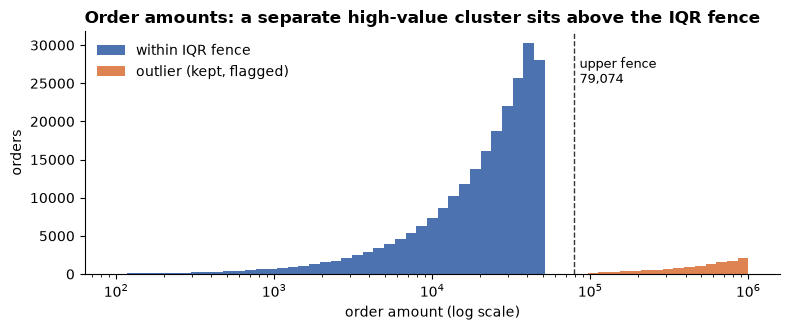

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(np.log10(valid.min()), np.log10(valid.max()), 60)
ax.hist(valid[valid <= upper], bins=bins, color="#4C72B0", label="within IQR fence")
ax.hist(valid[valid > upper], bins=bins, color="#DD8452", label="outlier (kept, flagged)")
ax.axvline(upper, color="#333333", linestyle="--", linewidth=1)
ax.text(upper * 1.08, ax.get_ylim()[1] * 0.9, f"upper fence\n{upper:,.0f}", fontsize=9, va="top")
ax.set_xscale("log")
ax.set_xlabel("order amount (log scale)")
ax.set_ylabel("orders")
ax.set_title("Order amounts: a separate high-value cluster sits above the IQR fence", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "m4_amount_distribution.png", dpi=150)
plt.show()

## 6. Order date

Raw dates come in several forms. Each form gets one explicit rule:

| Raw form | Rule |
|---|---|
| `YYYY-MM-DD` | valid, kept |
| `YYYY-MM-DDTHH:MM:SS.ffffff` | date part kept, then checked against the export date |
| `2024/31/01` | impossible (month 31): null, flagged |
| blank | null |
| a single date repeated on thousands of orders | placeholder: null, flagged |
| any date after the export day (2025-12-02) | impossible: null, flagged |

**Placeholder detection (NumPy):** a normal day has about 290 orders. Any one raw date text used more than 10 times the median daily count cannot be a real order date. This catches `31-12-2023` (18,050 orders) and `2025/01/10 12:00` (17,952 orders, also ambiguous between 10 January and 1 October). Keeping them would create two fake spikes in any sales chart.

In [7]:
od = stripped["order_date"]
is_iso = od.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
is_ts = od.str.fullmatch(r"\d{4}-\d{2}-\d{2}T[\d:.]+")

# normal daily volume = median count of the plain YYYY-MM-DD dates (timestamps are unique per order, so they are left out)
_, iso_counts = np.unique(od[is_iso].to_numpy(dtype=str), return_counts=True)
median_daily = np.median(iso_counts)
values, counts = np.unique(od[od.ne("")].to_numpy(dtype=str), return_counts=True)
placeholder_dates = {str(v) for v in values[counts > 10 * median_daily]} - {"2024/31/01"}  # impossible date handled on its own
print(f"median orders per day: {median_daily:.0f}; placeholder dates: {sorted(placeholder_dates)}")
is_placeholder = od.isin(placeholder_dates)
is_impossible = od.eq("2024/31/01")

parsed = pd.to_datetime(od.where(is_iso | is_ts).str[:10], format="%Y-%m-%d", errors="coerce")
is_future = parsed >= AFTER_SNAPSHOT
orders["order_date"] = parsed.where(~is_future & ~is_placeholder)

flag(is_impossible, "order_date", "impossible date (month 31); set to null")
flag(is_placeholder, "order_date", "placeholder date repeated on thousands of orders; set to null")
flag(is_future, "order_date", "date after the data export (2025-12-02); set to null")

log_fix(iid("order_date", "impossible date"), "Set to null and flagged", flagged=is_impossible.sum())
log_fix(iid("order_date", "date in DD-MM-YYYY"), "Repeated placeholder date: set to null and flagged",
        flagged=(is_placeholder & od.str.fullmatch(r"\d{2}-\d{2}-\d{4}")).sum())
log_fix(iid("order_date", "date with time in YYYY/MM/DD"), "Repeated placeholder date (and ambiguous): set to null and flagged",
        flagged=(is_placeholder & od.str.contains("/")).sum())
log_fix(iid("order_date", "full timestamp"), "Date part kept (all of these were future dates, see next row)",
        fixed=(is_ts & ~is_future).sum())
log_fix(iid("order_date", "order date after the data export"), "Set to null and flagged", flagged=is_future.sum())
log_fix(iid("order_date", "blank value"), "Kept as null (no source to fill)", flagged=0)

check_forms = (is_iso | is_ts | is_placeholder | is_impossible | od.eq("")).all()
assert check_forms, "an unexpected date form exists"
print(f"valid order dates: {orders['order_date'].notna().sum():,} | range {orders['order_date'].min().date()} to {orders['order_date'].max().date()}")

median orders per day: 287; placeholder dates: ['2025/01/10 12:00', '31-12-2023']
valid order dates: 210,000 | range 2023-12-03 to 2025-12-01


## 7. Quantity

| Raw | Rule |
|---|---|
| `1`-`5` | kept |
| `2.0` | whole number with `.0`: converted to `2` |
| `five` | number word: converted to `5` |
| `-3`, `0` | impossible quantity: null, flagged |
| blank | null |

`np.select` applies the rules in one vectorised step.

In [8]:
q_text = stripped["quantity"]
q_num = pd.to_numeric(q_text, errors="coerce")
WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10}
word_num = q_text.str.lower().map(WORDS)

is_word = word_num.notna()
is_decimal_whole = q_text.str.contains(".", regex=False) & q_num.notna() & q_num.eq(np.floor(q_num))
is_bad = q_num.le(0)

orders["quantity"] = pd.array(np.select(
    [is_word, is_bad, q_num.gt(0) & q_num.eq(np.floor(q_num))],
    [word_num, np.nan, q_num],
    default=np.nan,
), dtype="Int64")

unknown = q_text.ne("") & orders["quantity"].isna() & ~is_bad
assert not unknown.any(), q_text[unknown].unique()
flag(q_num.lt(0), "quantity", "negative quantity; set to null")
flag(q_num.eq(0), "quantity", "zero quantity; set to null")

log_fix(iid("quantity", "quantity written as a word"), "Converted word to number", fixed=is_word.sum())
log_fix(iid("quantity", "quantity with decimal"), "Converted .0 decimal to whole number", fixed=is_decimal_whole.sum())
log_fix(iid("quantity", "negative quantity"), "Set to null and flagged", flagged=q_num.lt(0).sum())
log_fix(iid("quantity", "zero quantity"), "Set to null and flagged", flagged=q_num.eq(0).sum())
log_fix(iid("quantity", "blank value"), "Kept as null (no source to fill)", flagged=0)

mappings["quantity"] = (
    pd.DataFrame({"raw_value": raw["quantity"], "clean_value": orders["quantity"].astype("string").fillna("(null)")})
    .value_counts().rename("rows").reset_index()
)
orders["quantity"].value_counts(dropna=False).sort_index()

quantity
1       44765
2       60270
3       45296
4       45058
5       59744
<NA>    44867
Name: count, dtype: Int64

## 8. Relationships

M1 found no orphan orders. This is re-checked against the **cleaned** customer and product tables.

In [9]:
orphan_customer = ~orders["customer_id"].isin(customers["customer_id"])
orphan_product = ~orders["product_id"].isin(products["product_id"])
print(f"orders with unknown customer: {orphan_customer.sum():,} | unknown product: {orphan_product.sum():,}")
assert not orphan_customer.any() and not orphan_product.any()

orders with unknown customer: 0 | unknown product: 0


## 9. Final table and validation

Every flag gets a `flag_type`, so the client sees at once what needs a decision:
- **needs review**: a person should check or decide (possible duplicate, suspicious value)
- **invalid or missing value**: the source value was impossible, a placeholder or blank; it was removed or left unconverted and cannot be recovered
- **auto-fixed (info)**: the value was repaired automatically and is listed for transparency

In [10]:
flag_table = pd.concat(flags, ignore_index=True)
flag_table["flag_type"] = np.select(
    [flag_table["reason"].str.endswith("set to null"), flag_table["reason"].str.contains("needs review")],
    ["invalid or missing value", "needs review"], default="",
)
assert flag_table["flag_type"].ne("").all(), flag_table.loc[flag_table["flag_type"].eq(""), "reason"].unique()
flag_table = flag_table[["order_id", "flag_type", "column", "raw_value", "reason"]]
dq = flag_table.groupby("order_id")["reason"].agg("; ".join)
review_ids = set(flag_table.loc[flag_table["flag_type"].eq("needs review"), "order_id"])

orders_clean = orders.assign(
    needs_review=orders["order_id"].isin(review_ids),
    dq_flags=orders["order_id"].map(dq).fillna(""),
)[[
    "order_id", "customer_id", "product_id", "order_date", "order_amount", "is_amount_outlier",
    "quantity", "payment_method", "status", "needs_review", "dq_flags",
]]

checks = {
    "300,000 orders, order_id unique": len(orders_clean) == len(raw) and orders_clean["order_id"].is_unique,
    "amounts positive or null": orders_clean["order_amount"].dropna().gt(0).all(),
    "dates within 2023-12-03 .. 2025-12-02 or null":
        orders_clean["order_date"].dropna().between("2023-12-03", "2025-12-02").all(),
    "no date holds more than 10x the median daily count":
        orders_clean["order_date"].value_counts().max() <= 10 * orders_clean["order_date"].value_counts().median(),
    "quantity whole number 1-5 or null": orders_clean["quantity"].dropna().between(1, 5).all(),
    "payment method standard": orders_clean["payment_method"].isin(["card", "cash", "upi", "wallet"]).all(),
    "status standard": orders_clean["status"].isin(["success", "failed", "refunded"]).all(),
    "every order links to a customer and a product": not (orphan_customer.any() or orphan_product.any()),
    "every M4 issue handled in fix log": set(pd.DataFrame(fix_log)["issue_id"]) == set(m4_issues["issue_id"]),
}
validation = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
assert validation["passed"].all(), validation
validation

,check,passed
0,"300,000 orders, order_id unique",True
1,amounts positive or null,True
2,dates within 2023-12-03 .. 2025-12-02 or null,True
3,no date holds more than 10x the median daily c...,True
4,quantity whole number 1-5 or null,True
5,payment method standard,True
6,status standard,True
7,every order links to a customer and a product,True
8,every M4 issue handled in fix log,True


In [11]:
completeness = orders_clean.notna().mean().mul(100).round(2).rename("% filled")
print(completeness.to_string())
print(f"\norders with at least one review flag: {orders_clean['dq_flags'].ne('').sum():,}")
print(f"orders that need review: {orders_clean['needs_review'].sum():,}")
flag_table.groupby(["flag_type", "reason"]).size().rename("rows")

order_id             100.00
customer_id          100.00
product_id           100.00
order_date            70.00
order_amount          82.82
is_amount_outlier    100.00
quantity              85.04
payment_method       100.00
status               100.00
needs_review         100.00
dq_flags             100.00

orders with at least one review flag: 138,740
orders that need review: 12,883


flag_type                 reason                                                       
invalid or missing value  date after the data export (2025-12-02); set to null             17974
                          impossible date (month 31); set to null                          18110
                          negative amount; set to null                                     12810
                          negative quantity; set to null                                   14939
                          placeholder date repeated on thousands of orders; set to null    36002
                          placeholder text 'NaN'; set to null                              12830
                          thousand-separator placeholder '1,200'; set to null              12897
                          zero amount; set to null                                         12988
                          zero quantity; set to null                                       14878
needs review              high outlier 

In [12]:
orders_clean.head(10)

,order_id,customer_id,product_id,order_date,order_amount,is_amount_outlier,quantity,payment_method,status,needs_review,dq_flags
0,06b5aa88-f86f-4e07-8e4b-6df36402c209,0a331d4c-a73d-4271-83ac-2f6726635495,PROD-0060,2025-07-29,473.82,False,1,wallet,success,False,
1,5b10b856-e084-471c-bc16-8dbab95e3f33,9e48263f-7923-4cb9-8138-b9da8eb85619,PROD-0393,NaT,17796.32,False,1,card,success,False,impossible date (month 31); set to null
2,88706122-160e-4721-b537-73cee232fcd5,245fac1f-5ac1-4448-acc9-70ff980a4e9b,PROD-0332,2024-03-02,31201.75,False,2,wallet,success,False,
3,c6ae75af-0313-4194-a788-8802515af2e4,abfda25e-6a38-4aa8-be24-cd22f371b2b0,PROD-0059,NaT,42282.89,False,2,wallet,refunded,False,
4,032ab1c7-8882-47d8-a2ac-fbefc1cfb2eb,e0010492-b072-4f48-abd6-8a87938fad24,PROD-0342,2024-02-11,27100.30,False,1,wallet,success,False,
5,0f2433b5-1f67-4446-9849-edff493026c2,bdf18b4d-db9f-46f0-8758-44a938529a49,PROD-0297,2025-11-09,2393.67,False,4,card,success,False,
6,71223631-9926-4ced-b994-60a6d97d1001,5380805b-1e8f-434c-a898-bfe678c2ea7a,PROD-0137,2025-12-01,12532.69,False,5,upi,success,False,
7,4acbdb89-3acd-40ff-ab86-87af982fcca8,a4bc8fc9-f452-43b3-a4c1-eaf7cec182ae,PROD-0010,2025-08-20,47079.63,False,2,card,success,False,
8,cc6dcafa-a53f-4be5-aee3-ec29d5994f0d,d7e5abd4-33ab-404f-adc1-de28fb6756ae,PROD-0243,2025-02-27,32901.99,False,5,upi,failed,False,
9,184ee64a-b795-4137-868f-9a90c6580ba2,b6a71ba1-8f4b-4f82-a131-c987879c104d,PROD-0084,2023-12-30,3858.55,False,3,upi,success,False,


## 10. Save outputs

In [13]:
def write_xlsx(path, sheets):
    with pd.ExcelWriter(path, engine="xlsxwriter", date_format="yyyy-mm-dd", datetime_format="yyyy-mm-dd") as writer:
        for name, data in sheets.items():
            data.to_excel(writer, sheet_name=name, index=False)
            ws = writer.sheets[name]
            ws.freeze_panes(1, 0)
            ws.autofilter(0, 0, len(data), len(data.columns) - 1)
            for i, col in enumerate(data.columns):
                width = data[col].head(2000).astype(str).str.len().max() if len(data) else 0
                ws.set_column(i, i, min(max(width, len(col)) + 2, 60))
    print("saved:", path.resolve())


fix_log_df = pd.DataFrame(fix_log)
mapping_sheet = pd.concat([m.assign(column=col) for col, m in mappings.items()], ignore_index=True)
mapping_sheet = mapping_sheet[["column", "raw_value", "clean_value", "rows"]]
write_xlsx(CLEAN_DIR / "orders_clean.xlsx", {
    "orders": orders_clean,
    "flagged": flag_table.sort_values(["flag_type", "reason", "order_id"]),
    "mappings": mapping_sheet,
})

CSV_DIR = CLEAN_DIR / "csv"
CSV_DIR.mkdir(exist_ok=True)
orders_clean.to_csv(CSV_DIR / "orders_clean.csv", index=False, encoding="utf-8", date_format="%Y-%m-%d")
print("saved CSV: orders_clean.csv")
write_xlsx(OUT_DIR / "m4_fix_log.xlsx", {"fix_log": fix_log_df, "validation": validation,
                                            "completeness": completeness.reset_index().rename(columns={"index": "column"})})
fix_log_df

saved: C:\Users\msibr\OneDrive\Upwork\customer360-data-cleaning\03_clean_data_and_report\clean_data\orders_clean.xlsx


saved CSV: orders_clean.csv
saved: C:\Users\msibr\OneDrive\Upwork\customer360-data-cleaning\02_process\04_cleaning_orders-pandas_numpy\output\m4_fix_log.xlsx


,issue_id,column,issue,rows_in_m1,rows_fixed,rows_flagged,action_taken
0,ISS-037,status,leading/trailing spaces,25658,25658,0,Trimmed
1,ISS-038,order_amount,leading/trailing spaces,25592,25592,0,Trimmed
2,ISS-039,payment_method,leading/trailing spaces,21553,21553,0,Trimmed
3,ISS-036,payment_method,"non-standard value (7 variants: case, typos, a...",75000,64178,0,"Mapped to ['card', 'cash', 'upi', 'wallet'] vi..."
4,ISS-035,status,"non-standard value (7 variants: case, typos, a...",90000,77064,0,"Mapped to ['failed', 'refunded', 'success'] vi..."
5,ISS-054,order_amount,placeholder text instead of a value,12830,0,12830,Set to null and flagged
6,ISS-052,order_amount,non-numeric amount (thousand separator) (all r...,12897,0,12897,Repeated placeholder: set to null and flagged
7,ISS-055,order_amount,negative amount (all rows hold the same value ...,12810,0,12810,Set to null and flagged
8,ISS-051,order_amount,zero amount (all rows hold the same value '0'),12988,0,12988,Set to null and flagged
9,ISS-053,order_amount,"high outlier (IQR rule, above 79,074.10)",12883,0,12883,Kept; marked is_amount_outlier and flagged
